# 01 · The SNUH cohort, niche labels and features

> Part of the DeepGraph-GBM walk-through. The project is a **benchmark**: it tests whether spatial graph neural networks improve supervised niche prediction in glioblastoma Visium data over matched graph-free models (they do not). See `docs/00_overview_and_roadmap.md`. Notebooks read `data/` (see `docs/WORKFLOW.md`, step A) and the tracked `results/`; none of them trains a model.

This notebook looks at the training cohort: how many sections, patients and spots there are, how the four
niche labels are assigned, how unbalanced they are, and what the 3,000-gene input looks like.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path("..").resolve()          # run from notebooks/
PRE = REPO / "data" / "preprocessed"
RES = REPO / "results"
NICHES = ["immune_cold", "immune_hot", "normal", "necrotic"]
COLORS = {"immune_cold": "#D55E00", "immune_hot": "#0072B2", "normal": "#009E73",
          "necrotic": "#CC79A7", "exclude": "#DDDDDD"}
pd.set_option("display.precision", 3)
import torch, yaml

## 1. Sections, patients and spots

In [2]:
meta = pd.read_csv(PRE / "sections_meta.csv")
print(f"sections: {len(meta)}   patients: {meta.patient.nunique()}   spots: {meta.n_spots.sum():,}"
      f"   labelled: {meta.n_labeled.sum():,} ({meta.n_labeled.sum() / meta.n_spots.sum():.0%})")
print(meta.source.value_counts().to_string())
meta.groupby("split").agg(patients=("patient", "nunique"), sections=("section", "size"),
                          spots=("n_spots", "sum"), labelled=("n_labeled", "sum"))

sections: 28   patients: 13   spots: 100,488   labelled: 75,697 (75%)
source
FFPE      23
Frozen     5


,patients,sections,spots,labelled
split,,,,
test,3,5,20033,16377
train,8,19,64213,45924
val,2,4,16242,13396


The atlas has 28 Visium sections (23 FFPE, 5 fresh-frozen) from 13 IDH-wildtype patients and
100,488 spots. About a quarter of spots get no niche label (vascular or discordant annotations). The
`split` column is the *primary* split used for Table 1. The primary analysis of the paper is
leave-one-patient-out, which uses every patient as a test patient once (notebook 02).

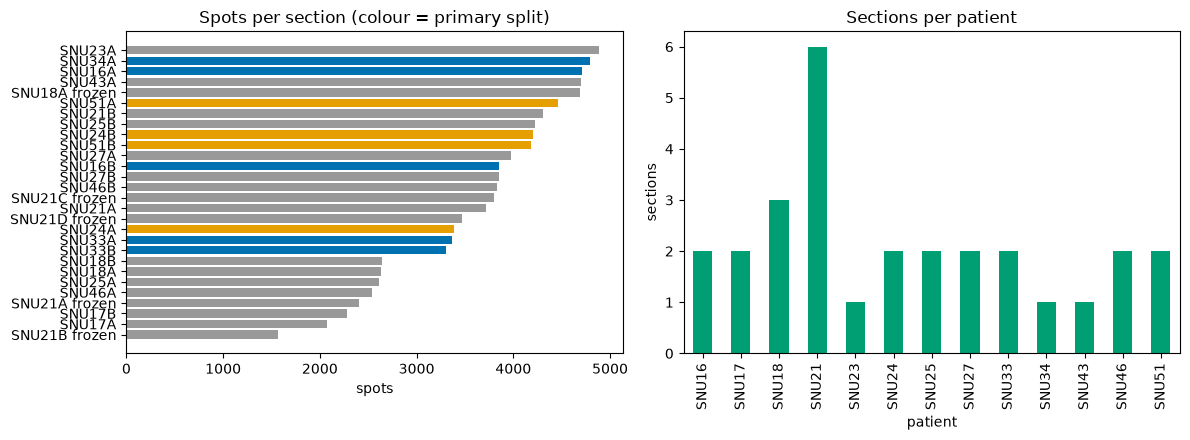

In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
m = meta.sort_values("n_spots")
a1.barh(m.section, m.n_spots, color=[{"train": "#999999", "val": "#E69F00", "test": "#0072B2"}[s] for s in m.split])
a1.set_xlabel("spots"); a1.set_title("Spots per section (colour = primary split)")
meta.patient.value_counts().sort_index().plot.bar(ax=a2, color="#009E73")
a2.set_ylabel("sections"); a2.set_title("Sections per patient")
plt.tight_layout(); plt.show()

Patients contribute up to six sections each, and sections from one patient share biology. Every split
in this project is therefore made **by patient**, never by spot or by section.

## 2. Label rules

In [4]:
rules = yaml.safe_load(open(REPO / "configs" / "labels.yaml"))
print("priority (first match wins):", " -> ".join(rules["priority"]))
for k in rules["priority"]:
    print(f"  {k:12s}", rules["niche_rules"][k])
print("MES-positive states:", rules["mes_states"])

priority (first match wins): necrotic -> immune_hot -> normal -> immune_cold
  necrotic     {'AF': ['PAN', 'PNZ']}
  immune_hot   {'metaprogram': ['immune'], 'not_AF': ['PAN', 'PNZ']}
  normal       {'AF': ['LE_GM', 'LE_WM'], 'metaprogram': ['LE_GM', 'LE_WM']}
  immune_cold  {'AF': ['CT', 'IT', 'IGN'], 'metaprogram': ['CT', 'IT', 'hypoxic']}
MES-positive states: ['MES (malig.)', 'MES.Hyp (malig.)', 'MES.Ast (malig.)']


These are **silver-standard** labels: rules applied to the atlas's own expression-derived annotations
(anatomical feature `AF` and `metaprogram`). A spot is `necrotic` if its anatomical feature is PAN/PNZ;
otherwise `immune_hot` if its metaprogram is immune; otherwise `normal` if *both* annotations are
leading-edge; otherwise `immune_cold` if both indicate tumour. Anything else is `exclude` and is masked from
training and scoring. Because the labels derive from expression, the paper also tests against
neuropathologist H&E labels in an independent cohort (notebook 06, section 5).

## 3. Class balance: across the atlas, by split, and by patient

In [5]:
graphs = torch.load(PRE / "graphs.pt", weights_only=False)
split_of = dict(zip(meta.patient, meta.split))
rows = []
for g in graphs:
    y = g.niche_y.numpy()
    for c, name in enumerate(NICHES):
        rows.append(dict(patient=g.patient, split=split_of[g.patient], niche=name, n=int((y == c).sum())))
counts = pd.DataFrame(rows)
by_split = counts.pivot_table(index="split", columns="niche", values="n", aggfunc="sum")[NICHES]
by_split["immune_hot %"] = 100 * by_split.immune_hot / by_split[NICHES].sum(axis=1)
by_split

niche,immune_cold,immune_hot,normal,necrotic,immune_hot %
split,,,,,
test,11125,185,1455,3612,1.130
train,12696,6485,17643,9100,14.121
val,8638,15,2715,2028,0.112


In [6]:
per_patient = counts.pivot_table(index="patient", columns="niche", values="n", aggfunc="sum")[NICHES]
per_patient.style.background_gradient(axis=None, cmap="Greys")

niche,immune_cold,immune_hot,normal,necrotic
patient,,,,
SNU16,3631,8,1081,3301
SNU17,2,709,0,3323
SNU18,2852,2996,481,592
SNU21,2500,381,4836,2549
SNU23,1686,215,2134,26
SNU24,4641,6,1757,163
SNU25,1006,1,3530,14
SNU27,2695,1203,504,2031
SNU33,2976,177,356,78


Two facts in these tables drive much of the paper:

* **Immune-hot is rare and very unevenly spread.** It is about 1% of the primary test spots, and the
  two primary validation patients have only 15 immune-hot spots between them. Per-class thresholds tuned
  on so few spots are poorly calibrated, which is why the six-split analysis is used only for variance
  (notebook 06).
* **Some patients are almost one class.** SNU46 is almost entirely `normal`, so its per-patient macro-F1
  is near zero for every model.

## 4. Features: 3,000 highly variable genes

In [7]:
hvg = json.load(open(PRE / "hvg_genes.json"))
markers = ["EGFR", "VEGFA", "CHI3L1", "CD44", "GFAP", "OLIG2", "SOX2", "MKI67", "PTEN", "GAPDH"]
print(f"{len(hvg):,} HVGs (seurat_v3 on expm1-reconstructed counts)")
pd.DataFrame({"gene": markers, "in panel": [m in hvg for m in markers]})

3,000 HVGs (seurat_v3 on expm1-reconstructed counts)


,gene,in panel
0,EGFR,True
1,VEGFA,True
2,CHI3L1,True
3,CD44,False
4,GFAP,False
5,OLIG2,False
6,SOX2,False
7,MKI67,False
8,PTEN,False
9,GAPDH,True


The panel is selected without labels, once, on the eight training patients of the primary split, and
reused in every fold of every analysis. Some familiar GBM markers are in it and some are not: the
`seurat_v3` criterion ranks variance relative to mean, not biological relevance. Every model sees exactly
the same panel, so the panel cannot favour one model over another.

## 5. The MES target

In [8]:
mes = torch.cat([g.mes_y for g in graphs]).numpy()
print(f"spots with an MES target: {np.isfinite(mes).sum():,} of {mes.size:,}")
print(f"MES-positive fraction:    {np.nanmean(mes):.1%}")
y16 = pd.read_csv(PRE / "SNU16A_spot_labels.csv")
print("\nSNU16A:", y16.niche.value_counts().to_dict(), f"| MES-positive {y16.mes.mean():.1%}")

spots with an MES target: 100,488 of 100,488
MES-positive fraction:    24.3%

SNU16A: {'immune_cold': 1746, 'necrotic': 1509, 'normal': 1042, 'exclude': 407, 'immune_hot': 8} | MES-positive 23.5%


The MES target is **binary**: 1 if a spot's annotated malignant state is mesenchymal-like (MES, MES.Hyp
or MES.Ast), otherwise 0. It is not a continuous score. The MES head is a secondary output; the benchmark's
conclusions rest on the niche classifier.